In [3]:
# Imports
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned data
df = pd.read_csv("../data/processed.csv.gz", compression="gzip")
df.head()

,id,title,text,label,content,clean_content
0,0,House Dem Aide: We Didn’t Even See Comey’s Let...,House Dem Aide: We Didn’t Even See Comey’s Let...,1,House Dem Aide: We Didn’t Even See Comey’s Let...,house aide didnt even see letter house aide di...
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Ever get the feeling your life circles the rou...,0,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",big woman campus ever get feeling life circle ...
2,2,Why the Truth Might Get You Fired,"Why the Truth Might Get You Fired October 29, ...",1,Why the Truth Might Get You Fired Why the Trut...,truth might get fired truth might get fired te...
3,3,15 Civilians Killed In Single US Airstrike Hav...,Videos 15 Civilians Killed In Single US Airstr...,1,15 Civilians Killed In Single US Airstrike Hav...,civilian single u video civilian single u rate...
4,4,Iranian woman jailed for fictional unpublished...,Print \nAn Iranian woman has been sentenced to...,1,Iranian woman jailed for fictional unpublished...,woman fictional unpublished story woman stoned...


In [4]:
df['clean_content'] = df['clean_content'].fillna('')

texts = df['clean_content']
y = df['label']

In [5]:
texts_train, texts_test, y_train, y_test = train_test_split(
    texts, y, test_size=0.2, random_state=42, stratify=y
)

vectorizer = TfidfVectorizer(max_features=5000, min_df=5)
X_train = vectorizer.fit_transform(texts_train)
X_test = vectorizer.transform(texts_test)

In [6]:
# Logistic Regression
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)
log_preds = log_model.predict(X_test)

# Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)

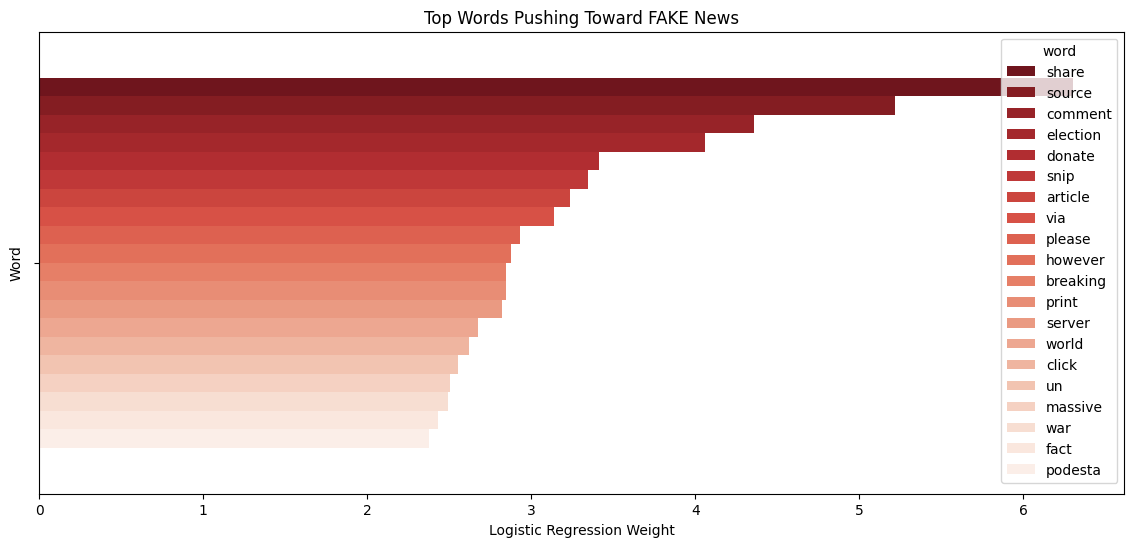

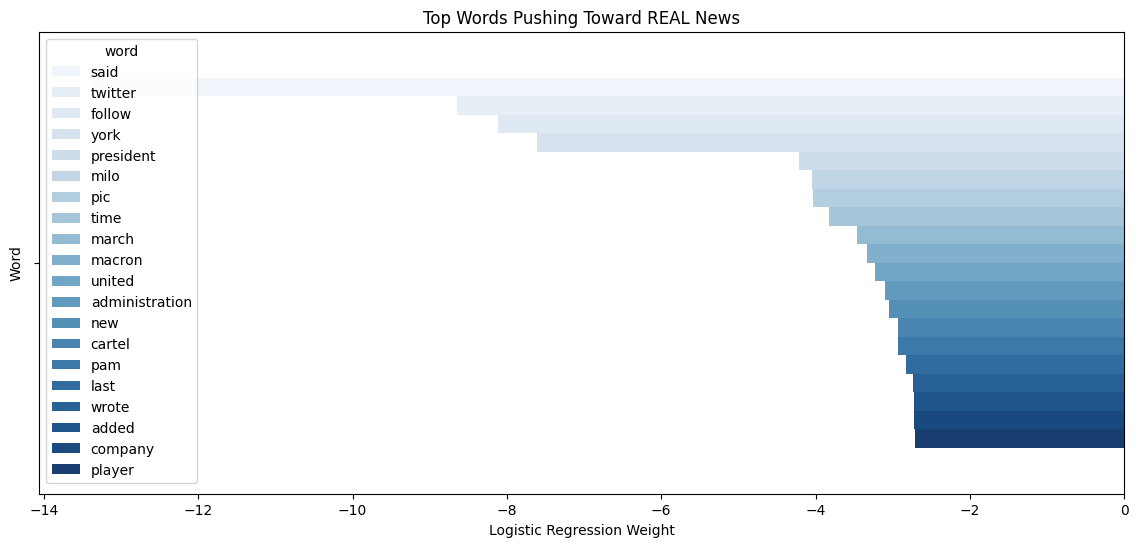

In [7]:
#Showing the top learned words from logistic regression

#Getting the feature names
feature_names = vectorizer.get_feature_names_out()

#Getting the model's learned weights
weights = log_model.coef_[0]  # Only one row since it's binary classification

#Combining into a dataframe
import pandas as pd

word_weights = pd.DataFrame({
    'word': feature_names,
    'weight': weights
})

#Visualizing top "Fake" vs "Real" indicators
import matplotlib.pyplot as plt
import seaborn as sns

# Top 20 words that push toward fake (positive weights)
top_fake = word_weights.sort_values(by='weight', ascending=False).head(20)

# Top 20 words that push toward real (negative weights)
top_real = word_weights.sort_values(by='weight', ascending=True).head(20)

# Plot
plt.figure(figsize=(14, 6))
sns.barplot(x='weight', hue='word', data=top_fake, palette='Reds_r', legend=True)
plt.title("Top Words Pushing Toward FAKE News")
plt.xlabel("Logistic Regression Weight")
plt.ylabel("Word")
plt.show()

plt.figure(figsize=(14, 6))
sns.barplot(x='weight', hue='word', data=top_real, palette='Blues', legend=True)
plt.title("Top Words Pushing Toward REAL News")
plt.xlabel("Logistic Regression Weight")
plt.ylabel("Word")
plt.show()

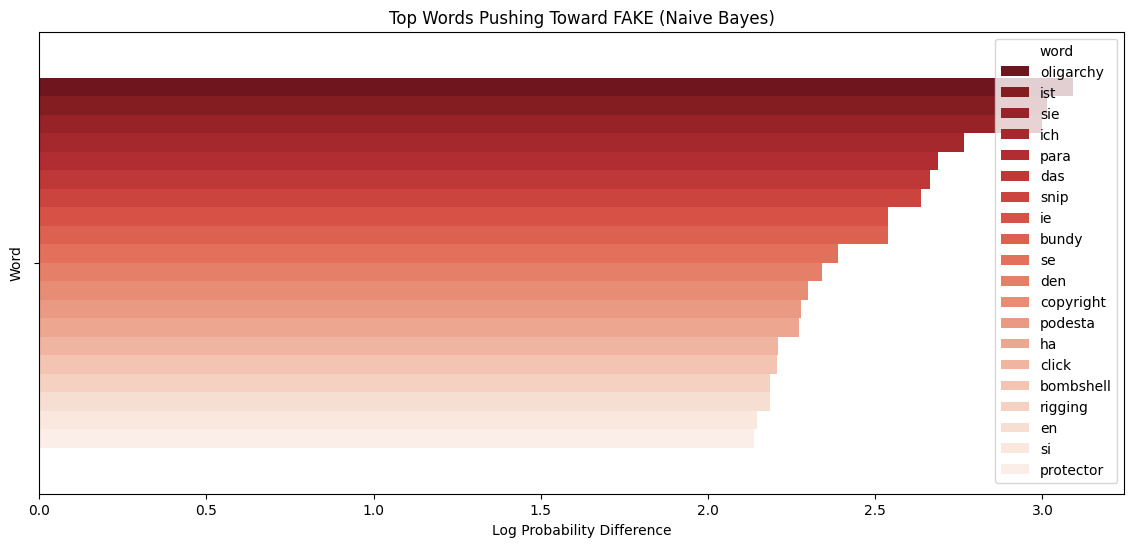

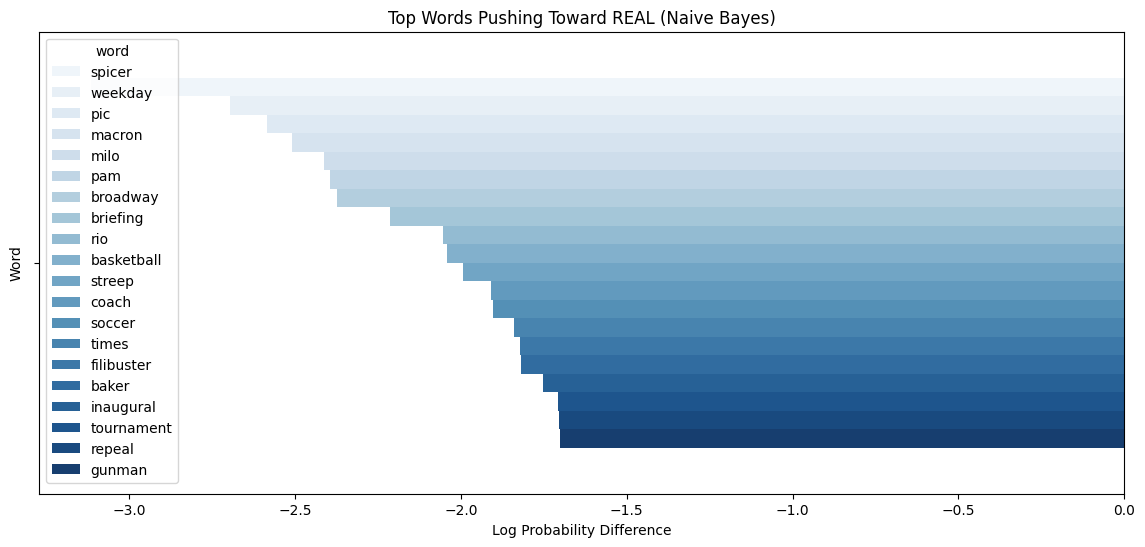

In [8]:
# Showing the top learned words from Naive Bayes

# Getting feature log probabilities
feature_names = vectorizer.get_feature_names_out()

# Get log probabilities for each word given the class
log_prob_fake = nb_model.feature_log_prob_[1]  # class 1 = fake
log_prob_real = nb_model.feature_log_prob_[0]  # class 0 = real

# Computing the difference between fake and real
import numpy as np

word_diff = log_prob_fake - log_prob_real  # Positive = more likely in fake

# Building a dataframe
nb_word_weights = pd.DataFrame({
    'word': feature_names,
    'log_prob_diff': word_diff
})

# Plotting the top indicators
# Top 20 fake-biased words
top_fake_nb = nb_word_weights.sort_values(by='log_prob_diff', ascending=False).head(20)

# Top 20 real-biased words
top_real_nb = nb_word_weights.sort_values(by='log_prob_diff', ascending=True).head(20)

# Plot
plt.figure(figsize=(14, 6))
sns.barplot(x='log_prob_diff', hue='word', data=top_fake_nb, palette='Reds_r', legend=True)
plt.title("Top Words Pushing Toward FAKE (Naive Bayes)")
plt.xlabel("Log Probability Difference")
plt.ylabel("Word")
plt.show()

plt.figure(figsize=(14, 6))
sns.barplot(x='log_prob_diff', hue='word', data=top_real_nb, palette='Blues', legend=True)
plt.title("Top Words Pushing Toward REAL (Naive Bayes)")
plt.xlabel("Log Probability Difference")
plt.ylabel("Word")
plt.show()

In [9]:
# Obtaining accuracy, precision, recall, F1 for both models

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def print_metrics(y_true, y_pred, model_name):
    print(f"📊 Performance for {model_name}")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall   :", round(recall_score(y_true, y_pred), 4))
    print("F1 Score :", round(f1_score(y_true, y_pred), 4))
    print("="*40)

print_metrics(y_test, log_preds, "Logistic Regression")
print_metrics(y_test, nb_preds, "Naive Bayes")

📊 Performance for Logistic Regression
Accuracy : 0.9205
Precision: 0.9157
Recall   : 0.9263
F1 Score : 0.9209
📊 Performance for Naive Bayes
Accuracy : 0.849
Precision: 0.8863
Recall   : 0.8005
F1 Score : 0.8412


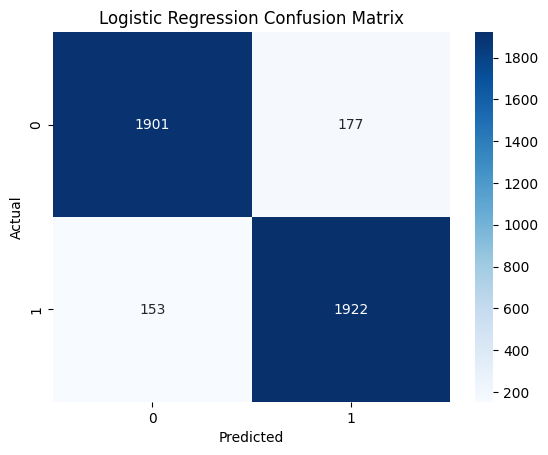

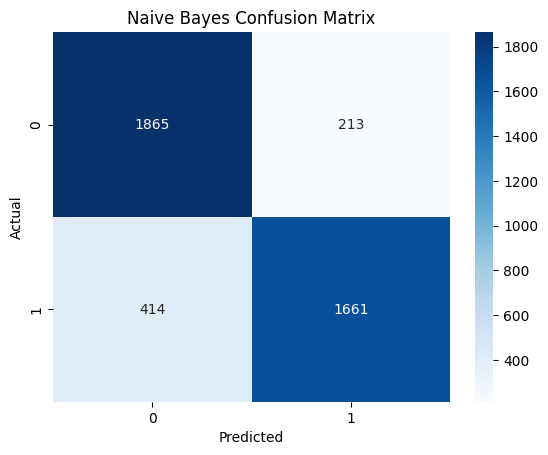

In [10]:
# Obtaining the confusion matrix for both models

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def plot_conf_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

plot_conf_matrix(y_test, log_preds, "Logistic Regression")
plot_conf_matrix(y_test, nb_preds, "Naive Bayes")

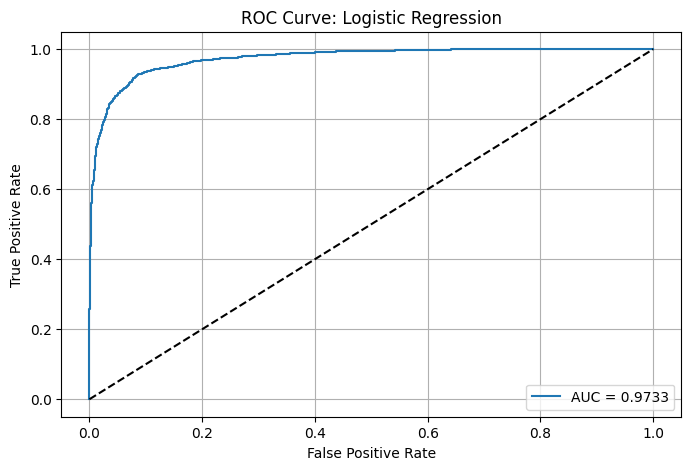

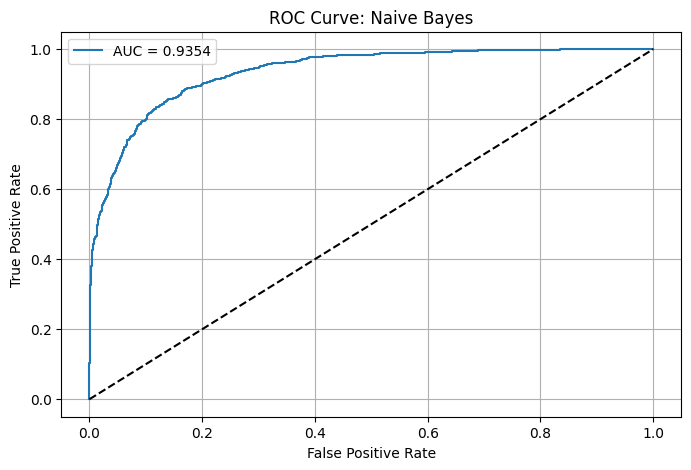

In [11]:
# Obtaining ROC AUC + Curve for both models

from sklearn.metrics import roc_auc_score, roc_curve

def plot_roc_curve(model, X_test, y_test, model_name):
    probs = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)

    plt.figure(figsize=(8, 5))
    plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve: {model_name}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_roc_curve(log_model, X_test, y_test, "Logistic Regression")
plot_roc_curve(nb_model, X_test, y_test, "Naive Bayes")

📊 Performance for Random Forest
Accuracy : 0.9203
Precision: 0.9233
Recall   : 0.9166
F1 Score : 0.92


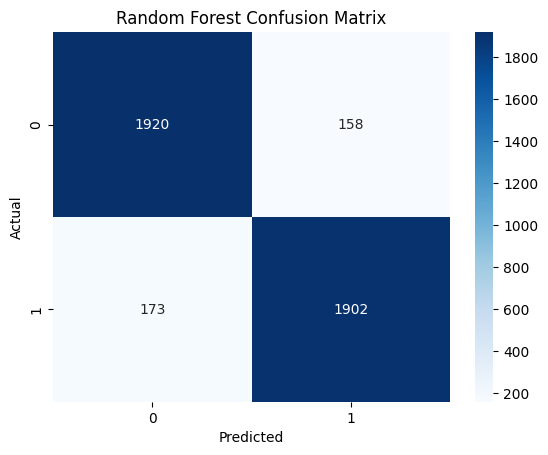

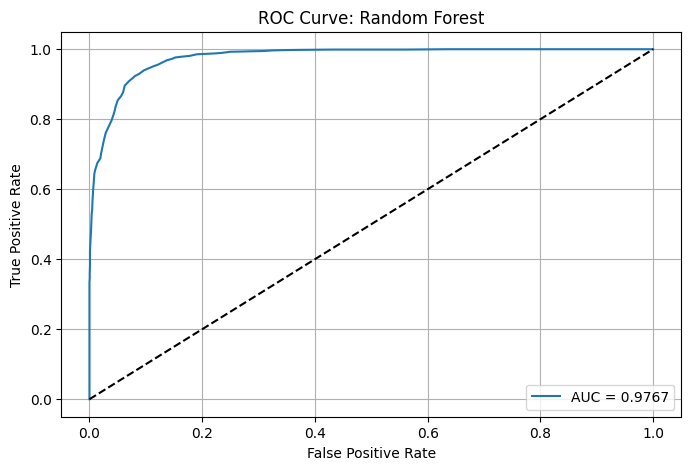

📊 Performance for XGBoost
Accuracy : 0.9388
Precision: 0.9249
Recall   : 0.9552
F1 Score : 0.9398


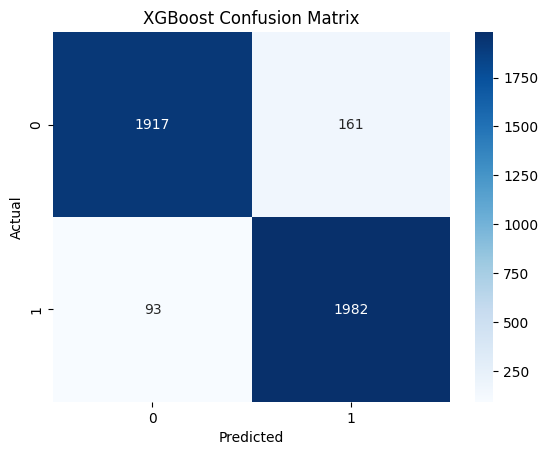

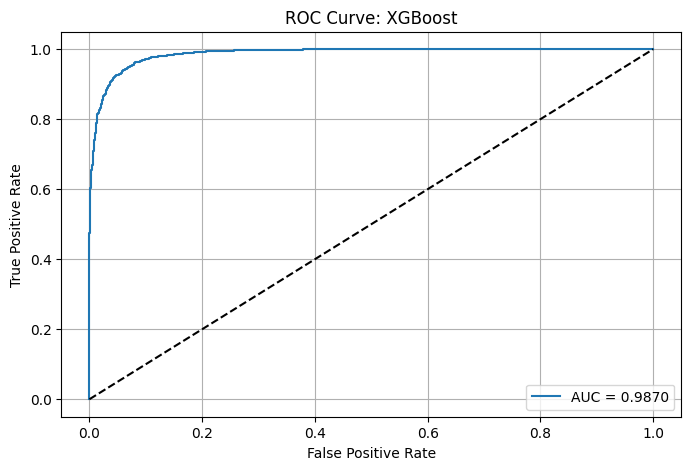

In [12]:
# Testing Random Forest and XGBoost

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Training Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# Training XGBoost
xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

# Evaluating Random Forest and XGBoost
print_metrics(y_test, rf_preds, "Random Forest")
plot_conf_matrix(y_test, rf_preds, "Random Forest")
plot_roc_curve(rf_model, X_test, y_test, "Random Forest")

print_metrics(y_test, xgb_preds, "XGBoost")
plot_conf_matrix(y_test, xgb_preds, "XGBoost")
plot_roc_curve(xgb_model, X_test, y_test, "XGBoost")

In [13]:
# Saving the models

import pickle
import os

# Make sure the /models directory exists
os.makedirs('../models', exist_ok=True)

# Save XGBoost model
with open('../models/xgb_model.pkl', 'wb') as f:
    pickle.dump(xgb_model, f)

# Save TF-IDF vectorizer
with open('../models/tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)

print("✅ Model and vectorizer saved to /models/")

✅ Model and vectorizer saved to /models/
